In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [5]:
df = pd.read_csv('car data.csv')

print("Dataset Loaded Successfully")

print(df.head())

Dataset Loaded Successfully
  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  


In [6]:
# Display first 5 records
print(df.head())

# Display last 5 records
print(df.tail())

# Dataset shape
print("Shape:", df.shape)

# Column names
print("Columns:", df.columns)

# Dataset information
df.info()

# Statistical summary
print(df.describe())

# Missing values
print(df.isnull().sum())

# Duplicate records
print("Duplicates:", df.duplicated().sum())

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
    Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
296     city  2016           9.50           11.6       33988    Diesel   
297     brio  2015           4.00            5.9       60000    Petrol   
298     city  2009           3.35           11.0       87934    Petrol   
299     city  2017          11.50           12.5       

In [7]:
# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check final dataset shape
print("Final Shape:", df.shape)

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64
Final Shape: (299, 9)


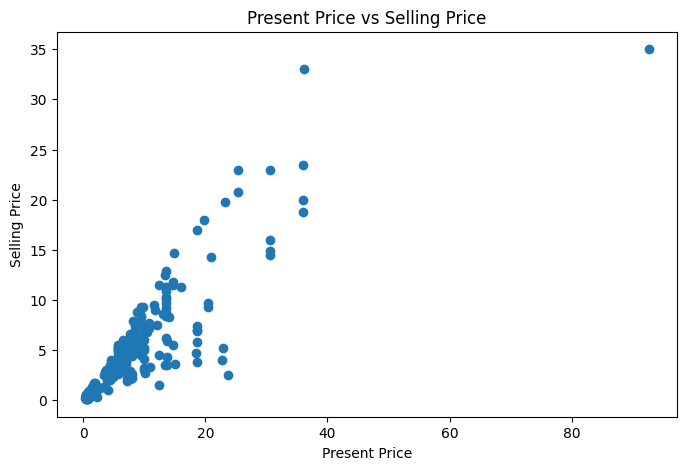

In [8]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['Present_Price'],
    df['Selling_Price']
)

plt.xlabel('Present Price')
plt.ylabel('Selling Price')
plt.title('Present Price vs Selling Price')

plt.show()

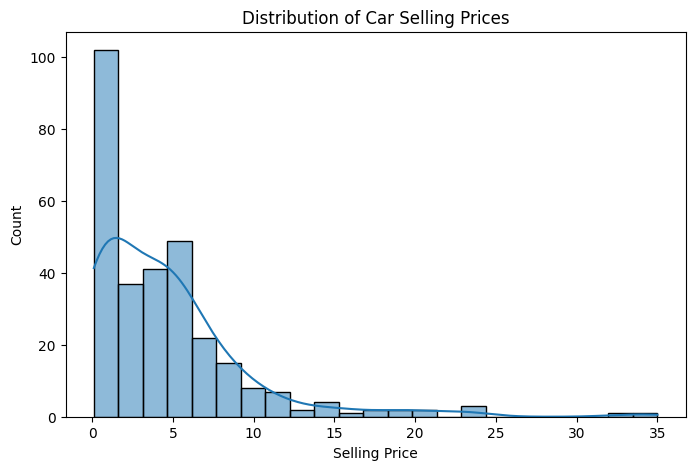

In [9]:
plt.figure(figsize=(8,5))

sns.histplot(df['Selling_Price'], kde=True)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')

plt.show()

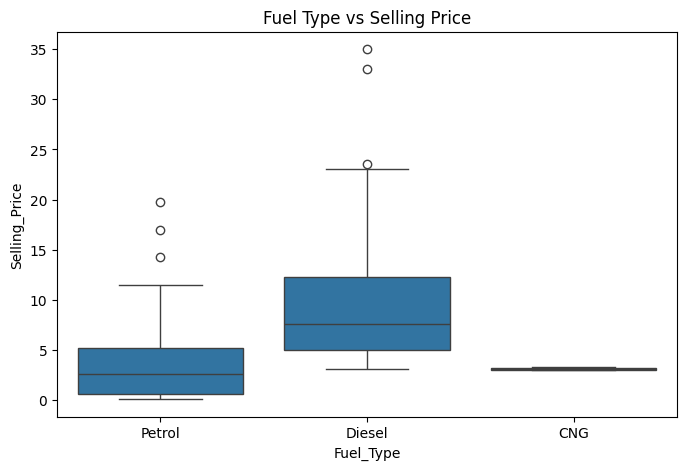

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Fuel_Type',
    y='Selling_Price',
    data=df
)

plt.title('Fuel Type vs Selling Price')

plt.show()

In [11]:
X = df[
    [
        'Year',
        'Present_Price',
        'Kms_Driven',
        'Fuel_Type',
        'Seller_Type',
        'Transmission',
        'Owner'
    ]
]

y = df['Selling_Price']

print("Input Features:")
print(X.head())

print("Target:")
print(y.head())

Input Features:
   Year  Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner
0  2014           5.59       27000    Petrol      Dealer       Manual      0
1  2013           9.54       43000    Diesel      Dealer       Manual      0
2  2017           9.85        6900    Petrol      Dealer       Manual      0
3  2011           4.15        5200    Petrol      Dealer       Manual      0
4  2014           6.87       42450    Diesel      Dealer       Manual      0
Target:
0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (239, 7)
Testing Data: (60, 7)


In [13]:
categorical_features = [
    'Fuel_Type',
    'Seller_Type',
    'Transmission'
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            'encoder',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            ),
            categorical_features
        )
    ],
    remainder='passthrough'
)

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train model
model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [14]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(result.head(10))

   Actual Price  Predicted Price
0          8.99         7.501922
1          8.35         7.791521
2          0.45         1.366444
3          7.45         7.009419
4          5.25        11.163290
5          5.25         4.534102
6          5.85         8.492463
7          1.15         1.700782
8          9.25         8.824220
9          0.38        -0.963488


In [15]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)

Model Evaluation Results
MAE: 1.4728924140028485
MSE: 6.370752956818785
RMSE: 2.5240350545938908
R2 Score: 0.7528154215834659


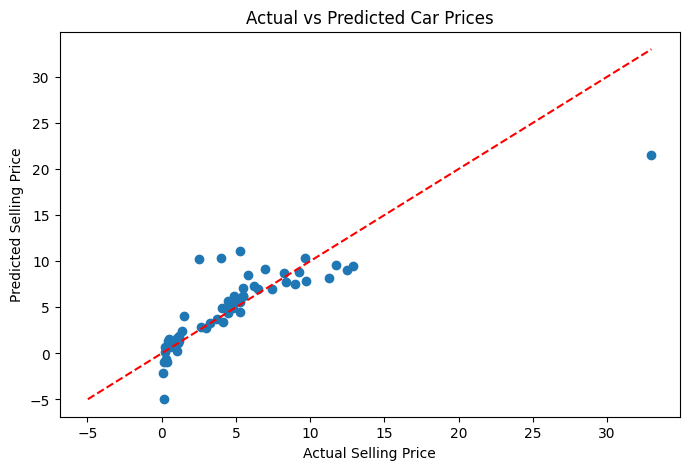

In [16]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')

plt.title('Actual vs Predicted Car Prices')

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    'r--'
)

plt.show()

In [17]:
new_car = pd.DataFrame([{
    'Year': 2016,
    'Present_Price': 8.0,
    'Kms_Driven': 30000,
    'Fuel_Type': 'Petrol',
    'Seller_Type': 'Dealer',
    'Transmission': 'Manual',
    'Owner': 0
}])

prediction = model.predict(new_car)

print("Predicted Car Selling Price:",
      round(prediction[0], 2), "Lakhs")

Predicted Car Selling Price: 5.62 Lakhs


In [18]:
df.to_csv('cleaned_car_data.csv', index=False)

files.download('cleaned_car_data.csv')

print("Cleaned Dataset Downloaded Successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cleaned Dataset Downloaded Successfully!
